# Emberfall Movie Detective

A Claude tool-use agent for **tip-of-the-tongue** film search: you describe a half-remembered
film (English or Ukrainian), it finds the title, explains the match, points out details you
probably misremember, and can save it to a watchlist. The same tools are served over MCP.

UCU NLP course, Assignment 1. Built on the owner's iOS app **Emberfall**, whose search
pipeline is the baseline. Sections follow CRISP-DM. All numbers come from saved evaluation
files in `evals/results/`; LLM calls replay from the disk cache, so this notebook runs
without an API key.

## 0. Setup

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # One zip holds the repository, the catalog, the E3 model and the caches (docs/COLAB_ASSETS.md).
    # It is downloaded from a shared Google Drive link: no Drive access is needed.
    BUNDLE_ID = "1OsDhPC5UjxfKSLCpwVF5rPZsh3sjGyA8"
    REPO = "/content/emberfall_detective"
    if not os.path.exists(REPO):
        !gdown -q {BUNDLE_ID} -O /content/bundle.zip
        !unzip -q /content/bundle.zip -d /content
    %cd {REPO}
    import importlib.metadata as md
    loaded = {m: sys.modules[m].__version__ for m in ("numpy", "pandas", "torch") if m in sys.modules}
    %pip install -q -e .
    changed = [m for m, v in loaded.items() if md.version(m) != v]
    if changed:  # Colab had older versions in memory: a restart loads the installed ones
        raise SystemExit(f"Installed {changed}: Runtime -> Restart session, then Run all again "
                         "(the second time this cell skips the unzip and the install is instant).")
else:
    while not os.path.exists("pyproject.toml"):
        os.chdir("..")
sys.path.insert(0, os.getcwd())

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120, "display.width", 200)
from evals import report

## 1. Business understanding

**User need.** "I remember a movie but not its title" (detective mode) and "something like
this" (discovery). People describe plot fragments, scenes, mood and where they watched it;
they hedge, exclude ("not the remake") and misremember (wrong actor, wrong decade).

**Success criteria** (brief section 2): the intended title in the top 10, ideally first
(Success@k, MRR); no shown title violates a stated constraint; no hallucinated titles (every
title resolves to a catalog/TMDB id); explanations claim only what the title's text supports;
vague requests get at most 1-2 targeted questions; Ukrainian close to English.

**Baseline (Emberfall today).** Free tier: a Claude call parses the request, then one SQL
function fuses gte-small vector search with Postgres full-text search (RRF, popularity nudge,
40 results). Catalog: 18,225 titles from 2000-2026, documents mostly TMDB blurbs. Known
weaknesses (W1-W9) are listed in `docs/PROJECT_BRIEF.md`; several are tested below.

**Out of scope:** streaming availability, the iOS UI, accounts.

## 2. Data understanding

**Catalog.** The Supabase export was extended with a Wikipedia intro for every title
(`doc_wiki`) and with the most-voted films and shows of 1950-1999 (ToT queries often target
older films). Coverage, document lengths in E3 tokens and the W7 check
(`data/eda_catalog.py`):

In [2]:
import json, glob
eda = json.loads(open(sorted(glob.glob("evals/results/eda/*.json"))[-1]).read())
display(pd.DataFrame({"rows": eda["coverage"]["rows"], "with Wikipedia intro": eda["coverage"]["wiki_share"]}))
tokens = {k: v for k, v in eda["tokens"].items() if k != "max_seq_length"}
display(pd.DataFrame(tokens).T.round(3))
print("W7 (were stored vectors built from doc or from title. overview?):", eda["w7"])

,rows,with Wikipedia intro
emberfall/movie,11041,0.9510
emberfall/tv,7184,0.8171
extension/movie,5000,0.9936
extension/tv,1751,0.9195


,p50,p95,max,share_over_256,share_over_512
doc/emberfall/movie,90.0,160.00,615.0,0.005,0.001
doc/emberfall/tv,86.0,195.00,589.0,0.013,0.001
doc_wiki/emberfall/movie,178.0,449.00,660.0,0.260,0.024
doc_wiki/emberfall/tv,160.0,430.85,660.0,0.216,0.021
doc_wiki/extension/movie,207.0,478.00,636.0,0.337,0.036
doc_wiki/extension/tv,191.0,488.50,624.0,0.328,0.041


W7 (were stored vectors built from doc or from title. overview?): {'model': 'thenlper/gte-small', 'rows_compared': 18208, 'cos_to_doc_p1_p50': [0.9972, 0.9987], 'cos_to_title_overview_p50_p99': [0.9727, 0.9967], 'closer_to_title_overview': 0}


**Known-item queries.** TREC ToT 2023 test and 2024 test (via the 2025 release), the splits
the retriever never saw (TREC ToT 2023 train/dev selected E3 in Colab). Answers are Wikipedia
pages, linked to TMDB through Wikidata. How many answers does the catalog contain?

In [3]:
from evals.gold import load
ki = pd.DataFrame([e.model_dump() for e in load("known_item")])
display(pd.crosstab([ki.source, ki.split], ki.in_catalog, margins=True))

in_catalog                        False  True  All
source                     split                  
dataset:trec-tot-2023-test dev       46    30   76
                           test      33    33   66
dataset:trec-tot-2024-test dev       47    85  132
                           test      55    90  145
All                                 181   238  419

## 3. Data preparation

**Documents.** `doc` (baseline: title, genres, 15 TMDB keywords, mostly the TMDB overview) vs
`doc_wiki` (same format, English Wikipedia intro when one exists).

**Gold sets** (`evals/gold/*.jsonl`, schemas in `evals/gold.py`, split by a hash of the id so
no example ever moves between dev and test). Sources: public datasets first; then sets built
in code without an LLM; agent-drafted or LLM-drafted sets are labelled as such.

In [4]:
from evals.gold import SCHEMAS
rows = []
for name in SCHEMAS:
    try:
        for e in load(name):
            rows.append({"set": name, "split": e.split, "source": e.source.split(":")[0]})
    except FileNotFoundError:
        pass
display(pd.crosstab([pd.Series([r["set"] for r in rows], name="set"),
                     pd.Series([r["source"] for r in rows], name="source")],
                    pd.Series([r["split"] for r in rows], name="split")))

,split,dev,test
set,source,,
agent_decision,agent_drafted,27,36
details,dataset,68,81
false_memory,synthetic,60,60
known_item,dataset,208,211
known_item_uk,llm_draft,50,50
similar_pairs,dataset,68,81
title_lookup,dataset,258,236
watchlist_scenario,agent_drafted,9,7


## 4. Modeling

```
user message (EN/UK)
  -> C0 normalize            language id, Unicode clean-up
  -> C1 agent (Haiku 5.5)    tool loop, max 4 tool calls per turn, ends with `respond`
       tools (also over MCP):
       C4 search_catalog     E3 dense top-100 over doc_wiki (filters applied first)
                              -> C5 Haiku listwise rerank of the top 20
       C6 find_title         fuzzy title match (typos), TMDB for Ukrainian titles
       C7 similar_to         neighbours of the title's E3 vector
       C8 get_title_details  TMDB runtime, cast, director
       C9 watchlist          SQLite; add/remove only after the user confirms (enforced in code)
       C10 external_lookup   TMDB for guesses, then Claude web search (max 2); TMDB-resolved only
  -> picks: only ids a tool returned (hallucination guard)
  -> C2 clues (Haiku)        the user's memory as tagged clues
  -> C11 verifier (Haiku)    each clue supported / contradicted / not mentioned; false memory
  -> C12 explain (Sonnet)    1-2 sentences grounded in the evidence
C3 clarifier: one question that splits close candidates (evaluated with a user simulator).
```

In [5]:
from concierge.tools.registry import TOOLS
display(pd.DataFrame([{"tool": t.name, "writes": t.writes, "agent only": t.agent_only,
                       "description (what the model reads)": t.description[:160] + "..."}
                      for t in TOOLS]).set_index("tool"))

/Users/ostappavlyshyn/Documents/emberfall-detective/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1115 22:45:26.471000 4240 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


,writes,agent only,description (what the model reads)
tool,,,
search_catalog,False,False,"Find films and TV shows in the catalog from a description of their plot, scenes, characters, setting or mood. Use it..."
find_title,False,False,"Resolve a title the user names to its id, e.g. 'Twister', 'Interstelar' (typo), 'Інтерстеллар' (Ukrainian). Use it b..."
similar_to,False,False,"Titles similar to one known title (by plot, setting and tone), with the same filters as search_catalog. Use it for '..."
get_title_details,False,False,"Facts about one title from TMDB: runtime, seasons, directors (creators for TV), cast, genres, keywords, overview. Us..."
watchlist,True,False,The user's watchlist. action=list shows it. action=add / remove only PROPOSES a change: nothing is saved until the u...
external_lookup,False,False,"Look outside the catalog when search_catalog found nothing convincing. Give the user's description and, if you suspe..."
respond,False,True,"End your turn: send the user your message, the titles you propose (picks), and answer options if you ask a question...."


**Retriever (done in Colab before this repo, brief 7.1).** gte-small fine-tuned (E3) on 5,905
synthetic ToT queries from Claude Haiku with hard negatives. On TREC ToT 2023 (231k Wikipedia
pages) it lifted Recall@100 from 0.213 to 0.313; with rerank depth 20 the end-to-end gain was
not significant (+0.002, CI [-0.055, +0.054]). Experiment notebooks: `notebooks/experiments/`.

**One query, end to end** (a known false memory: Tom Hanks is not in Twister):

In [6]:
from concierge.agent import DetectiveAgent
from concierge.finalize import verify_and_explain
from concierge.tools.registry import Toolbox
box = Toolbox.create(watchlist_path=":memory:")
agent = DetectiveAgent(box, finalize=verify_and_explain)
turn = agent.turn("A movie where storm chasers follow tornadoes across Oklahoma, I think Tom Hanks "
                  "was in it, and a cow flies past their truck")
print(turn.message, "\n")
for p in turn.picks[:2]:
    print(p.id, p.title, p.year, "|", (p.notes.get("verification") or {}).get("false_memory"))
    print("   ", p.notes.get("explanation"))
print("\ntools:", [c.name for c in turn.tool_calls], "| cost $", turn.cost_usd, "| s", turn.latency_s)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4911.68it/s]

That sounds like Twister (1996). I'm quite sure of it: storm chasers in Oklahoma, a truck, and the famous cow flying past. The detail that seems off is Tom Hanks. He isn't in it; the leads are Helen Hunt and Bill Paxton. If you want the 2024 sequel, Twisters is also in the catalog, but the cow moment is from the original. 

movie/664 Twister 1996 | None
    This looks like Twister, a 1996 disaster film about a group of storm chasers racing to deploy a tornado research device during a severe outbreak in Oklahoma. Tom Hanks isn't in the cast listed here (it stars Helen Hunt and Bill Paxton), and the flying cow isn't mentioned in the catalog details, so I can't confirm that part.
movie/718821 Twisters 2024 | None of the clues is clearly contradicted; the cast and scene details are simply absent from the evidence, so no false memory is identified.
    Twisters fits the storm chasers and the Oklahoma setting, since it follows rival groups of chasers investigating a tornado outbreak there. T

**MCP.** `claude mcp add emberfall -- uv --directory <repo> run python -m concierge.mcp_server`
serves the six data tools with the registry's schemas (low-level `Server` of mcp SDK 2.x).

In [7]:
display(report.metrics_table("mcp", "dev", ["stdio"]))

,n,parent,schema_identical,call_ok
config,,,,
stdio,6,None,"1.000 [1.00, 1.00]","1.000 [1.00, 1.00]"


## 5. Evaluation (dev split; the test split is run once, at the end)

Each row is one configuration; `parent` is the configuration it changes by exactly one factor.
Cells show the mean and the 95% bootstrap CI over queries.

**C4/C5 search_catalog + rerank** - from the deployed baseline to the chosen pipeline:

,parent,success@1,success@10,mrr@10,recall@100
config,,,,,
baseline,NaN,"0.139 [0.08, 0.20]","0.217 [0.15, 0.30]","0.164 [0.10, 0.23]","0.296 [0.22, 0.38]"
gte_doc,baseline,"0.130 [0.07, 0.20]","0.226 [0.15, 0.30]","0.158 [0.10, 0.22]","0.330 [0.24, 0.42]"
e3_doc,gte_doc,"0.191 [0.12, 0.27]","0.261 [0.18, 0.34]","0.219 [0.15, 0.29]","0.417 [0.33, 0.50]"
e3_docwiki,e3_doc,"0.200 [0.13, 0.28]","0.322 [0.23, 0.41]","0.239 [0.17, 0.32]","0.417 [0.33, 0.50]"
e3_docwiki_ext,e3_docwiki,"0.339 [0.25, 0.43]","0.504 [0.41, 0.59]","0.395 [0.31, 0.48]","0.678 [0.59, 0.77]"
e3_docwiki_ext_rr20,e3_docwiki_ext,"0.478 [0.39, 0.57]","0.591 [0.50, 0.68]","0.523 [0.44, 0.61]","0.678 [0.59, 0.77]"
e3_docwiki_ext_rr50,e3_docwiki_ext_rr20,"0.478 [0.38, 0.57]","0.600 [0.50, 0.69]","0.519 [0.43, 0.61]","0.678 [0.59, 0.77]"
e3_docwiki_ext_rr20_c1000,e3_docwiki_ext_rr20,"0.522 [0.43, 0.62]","0.591 [0.50, 0.68]","0.546 [0.46, 0.64]","0.678 [0.59, 0.77]"
tool_whole,e3_docwiki_ext_rr20_c1000,"0.522 [0.43, 0.62]","0.591 [0.50, 0.68]","0.546 [0.46, 0.64]","0.678 [0.59, 0.77]"


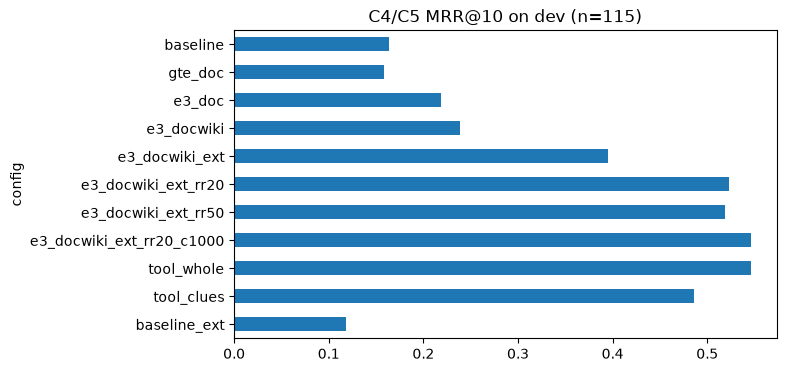

In [8]:
c4 = report.metrics_table("c4", "dev", report.C4_CHAIN)
display(c4[["parent", "success@1", "success@10", "mrr@10", "recall@100"]])
means = c4["mrr@10"].str.split().str[0].astype(float)
means.plot.barh(figsize=(7, 4), title="C4/C5 MRR@10 on dev (n=115)"); plt.gca().invert_yaxis(); plt.show()

In [9]:
display(report.group_table("c4", "dev", "tool_whole", ["success@1", "success@10", "mrr@10"]))

,n,success@1,success@10,mrr@10
source=dataset:trec-tot-2023-test,30.0,0.2000,0.3000,0.2278
source=dataset:trec-tot-2024-test,85.0,0.6353,0.6941,0.6588
answer_catalog=emberfall,71.0,0.4648,0.5493,0.4977
answer_catalog=extension,44.0,0.6136,0.6591,0.6250


**C0 language id, C1 agent decisions, C3 clarifier, C6 find_title, C7 similar_to, C8 details**

In [10]:
display(report.metrics_table("c0", "dev", ["default"]))
display(report.metrics_table("c1", "dev", ["default"])); print(report.extra("c1", "dev", "default"))
display(report.metrics_table("c3", "dev", ["default"])); print(report.extra("c3", "dev", "default"))
display(report.metrics_table("c6", "dev", ["wratio", "default", "catalog_only", "tmdb_always", "accept80"]))
display(report.group_table("c6", "dev", "default", ["success@1", "success@5"]))
display(report.metrics_table("c7", "dev", ["e3_docwiki", "gte_docwiki", "stored_doc"]))
display(report.metrics_table("c8", "dev", ["default"]))
display(report.metrics_table("c9", "dev", ["default"]))

,n,parent,lang_correct
config,,,
default,543,None,"1.000 [1.00, 1.00]"


,n,parent,action_correct,filters_exact,hallucinated_filter,query_recall
config,,,,,,
default,27,None,"0.926 [0.81, 1.00]","0.889 [0.72, 1.00]","0.000 [0.00, 0.00]","0.964 [0.92, 1.00]"


{'macro_f1': 0.6667, 'f1_per_action': {'ask_user': 0.0, 'find_title': 1.0, 'respond': 0.667, 'search_catalog': 1.0}, 'confusion': {'ask_user -> respond': 2, 'find_title -> find_title': 5, 'respond -> respond': 2, 'search_catalog -> search_catalog': 18}, 'clarify_mcc': 0.0}


,n,parent,s1_q0,s1_q1,s1_q2,answer_kept,redundant
config,,,,,,,
default,115,None,"0.522 [0.43, 0.62]","0.522 [0.43, 0.62]","0.530 [0.43, 0.62]","0.926 [0.85, 0.99]","0.444 [0.36, 0.53]"


{'gain_with_ci': {'s1_q1-s1_q0': [0.0, -0.0348, 0.0348], 's1_q2-s1_q0': [0.0087, -0.0435, 0.0609]}}


,n,parent,success@1,success@5
config,,,,
wratio,258,NaN,"0.942 [0.91, 0.97]","0.996 [0.99, 1.00]"
default,258,wratio,"0.977 [0.96, 0.99]","0.996 [0.99, 1.00]"
catalog_only,258,default,"0.977 [0.96, 0.99]","0.996 [0.99, 1.00]"
tmdb_always,258,default,"0.954 [0.93, 0.98]","0.996 [0.99, 1.00]"
accept80,258,default,"0.977 [0.96, 0.99]","0.996 [0.99, 1.00]"


,n,success@1,success@5
variant=clean,106.0,1.0000,1.0000
variant=typo,94.0,1.0000,1.0000
variant=uk,58.0,0.8966,0.9828
lang=en,200.0,1.0000,1.0000
lang=uk,58.0,0.8966,0.9828


,n,parent,ndcg@10,recall@10
config,,,,
e3_docwiki,68,NaN,"0.178 [0.13, 0.22]","0.110 [0.08, 0.14]"
gte_docwiki,68,e3_docwiki,"0.088 [0.06, 0.13]","0.053 [0.03, 0.07]"
stored_doc,68,gte_docwiki,"0.059 [0.03, 0.09]","0.036 [0.02, 0.05]"


,n,parent,director_match,director_fuzzy,runtime_within_3,under_120_agrees,year_within_1
config,,,,,,,
default,68,None,"0.940 [0.88, 0.99]","0.985 [0.96, 1.00]","0.831 [0.74, 0.92]","1.000 [1.00, 1.00]","1.000 [1.00, 1.00]"


,n,parent,db_correct,unconfirmed_write,proposal_correct
config,,,,,
default,9,None,"1.000 [1.00, 1.00]","0.000 [0.00, 0.00]","0.889 [0.67, 1.00]"


**C10 external lookup, C11 verifier, C12 explanations (judge + judge validation)**

In [11]:
display(report.metrics_table("c10", "dev", ["web"])); print(report.extra("c10", "dev", "web"))
display(report.metrics_table("c11", "dev", ["default"])); print(report.extra("c11", "dev", "default"))
display(report.metrics_table("c12", "dev", ["default"])); print(report.extra("c12", "dev", "default"))

,n,parent,rescue@1,rescue@3,web_searches,cost_usd
config,,,,,,
web,93,None,"0.398 [0.30, 0.49]","0.419 [0.32, 0.52]","1.925 [1.85, 1.99]","0.021 [0.02, 0.02]"


{'total_cost_usd': 1.973, 'cost_per_rescue_usd': 0.0506}


,n,parent,caught,named,flags_original
config,,,,,
default,60,None,"1.000 [1.00, 1.00]","1.000 [1.00, 1.00]","0.233 [0.13, 0.35]"


{'precision_proxy': 0.8108}


,n,parent,faithfulness,fully_faithful,relevancy
config,,,,,
default,100,None,"0.958 [0.94, 0.97]","0.750 [0.66, 0.83]","0.767 [0.74, 0.79]"


{'judge_human_kappa': 0.0, 'agreement': 0.9333, 'labelled_claims': 30, 'human_supported': 30, 'judge_supported': 28}


**End to end, and the English / Ukrainian gap**

In [12]:
display(report.metrics_table("e2e", "dev", ["default", "uk"]))
display(report.en_uk_gap("dev"))
display(report.group_table("e2e", "dev", "default", ["success@1", "success@5", "tool_calls", "cost_usd"]))

,n,parent,success@1,success@5,rr,dropped_picks,tool_calls,cost_usd,latency_s,questions
config,,,,,,,,,,
default,208,None,"0.471 [0.40, 0.54]","0.500 [0.43, 0.57]","0.486 [0.42, 0.55]","0.010 [0.00, 0.02]","2.000 [1.89, 2.12]","0.018 [0.02, 0.02]","22.403 [20.58, 24.23]","0.269 [0.19, 0.35]"
uk,50,None,"0.560 [0.42, 0.70]","0.640 [0.50, 0.78]","0.593 [0.46, 0.72]","0.000 [0.00, 0.00]","2.220 [2.04, 2.44]","0.021 [0.02, 0.03]","30.054 [27.55, 32.70]","0.140 [0.04, 0.28]"


,n,en,uk,uk - en,ci95
success@1,50,0.62,0.56,-0.06,"[-0.160, +0.020]"
success@5,50,0.68,0.64,-0.04,"[-0.160, +0.060]"
rr,50,0.65,0.593333,-0.056667,"[-0.143, +0.020]"


,n,success@1,success@5,tool_calls,cost_usd
catalog=in,115.0,0.6348,0.6609,1.6696,0.0137
catalog=out,93.0,0.2688,0.3011,2.4086,0.0232
source=dataset:trec-tot-2023-test,76.0,0.3684,0.3947,2.3026,0.0208
source=dataset:trec-tot-2024-test,132.0,0.5303,0.5606,1.8258,0.0164
lang=en,208.0,0.4712,0.5000,2.0000,0.0180


**Error analysis** - failed cases with the stage that lost the answer:

In [13]:
display(report.failed_cases("c4", "dev", "tool_whole", ["answer_title", "rank", "top3"], n=8))
display(report.failed_cases("e2e", "dev", "default", ["answer_title", "catalog", "tools", "picks"], n=8))

,id,answer_title,rank,top3
0,trec-tot-2023-test-1006,The Collector,NaN,"[movie/1216191, movie/1404791, movie/1008005]"
1,trec-tot-2023-test-126,Jeepers Creepers,NaN,"[movie/31646, movie/11351, movie/1180831]"
2,trec-tot-2023-test-200,The Island,31.0,"[movie/72710, movie/335866, movie/597890]"
3,trec-tot-2023-test-211,Hannibal Rising,NaN,"[movie/67740, movie/15356, movie/25155]"
4,trec-tot-2023-test-263,Father Frost,NaN,"[movie/266220, tv/29452, movie/365045]"
5,trec-tot-2023-test-328,Incendies,NaN,"[movie/48266, movie/801112, movie/166666]"
6,trec-tot-2023-test-457,A Woman Is a Woman,NaN,"[movie/2363, movie/1628, movie/2860]"
7,trec-tot-2023-test-464,Joe Versus the Volcano,NaN,"[movie/24452, movie/10776, movie/5559]"


,id,answer_title,catalog,tools,picks
0,trec-tot-2023-test-1006,The Collector,in,"[[search_catalog, external_lookup]]",[]
1,trec-tot-2023-test-150,Necronomicon,out,"[[search_catalog, external_lookup]]",[]
2,trec-tot-2023-test-162,Terror Toons,out,"[[search_catalog, external_lookup]]","[movie/15762 Night of the Creeps, movie/42251 Forbidden World]"
3,trec-tot-2023-test-173,Patlabor WXIII the Movie,out,"[[search_catalog, external_lookup], [search_catalog]]",[]
4,trec-tot-2023-test-201,Saint Sinner,out,"[[search_catalog, external_lookup]]",[]
5,trec-tot-2023-test-211,Hannibal Rising,in,"[[search_catalog, external_lookup]]",[movie/524247 The Intruder]
6,trec-tot-2023-test-223,Kamillions,out,"[[search_catalog, external_lookup, find_title]]","[movie/14510 From Beyond, movie/42251 Forbidden World]"
7,trec-tot-2023-test-224,Ænigma,out,"[[search_catalog, external_lookup]]",[movie/33990 Little Witches]


**Cost** (real API calls only; replays from the cache are free):

In [14]:
display(report.spend())

calls   cost_usd
model             prompt_version                    
claude-haiku-5-5  external-v1         573  11.743911
claude-sonnet-5-5 explain-v1          715   3.009528
claude-opus-5-5   judge-explain-v1    100   1.122333
claude-haiku-5-5  rerank-v1          1642   1.104884
                  agent-v4           1743   0.913365
claude-sonnet-5-5 translate-uk-v1     100   0.580848
claude-haiku-5-5  verify-v2           953   0.508475
claude-sonnet-5-5 judge-explain-v1    100   0.483628
claude-haiku-5-5  clues-v1            807   0.300564
                  simulator-v1        889   0.188568
                  agent-v3            250   0.132288
                  clarify-v2          416   0.114847
                  clarify-v1          359   0.102197
                  agent-v2            171   0.079074
                  verify-v1           122   0.071262
                  inject-v1           120   0.044843
                  agent-v1             36   0.007571

## 6. Demo

In [15]:
RUN_DEMO = IN_COLAB  # Gradio UI: new questions need EMBERFALL_CLAUDE_KEY and TMDB_API_KEY in Colab Secrets
if RUN_DEMO:
    %pip install -q gradio
    import gradio as gr
    from concierge import config
    for name in ("EMBERFALL_CLAUDE_KEY", "TMDB_API_KEY"):
        config.get_secret(name)  # read here, in the main thread; Gradio's workers reuse them
    demo_agent = DetectiveAgent(box, finalize=verify_and_explain)
    def chat(message, history):
        t = demo_agent.turn(message)
        lines = [t.message] + [f"- {p.title} ({p.year}): {p.notes.get('explanation', '')}" for p in t.picks]
        if t.options:
            lines.append("Options: " + " / ".join(t.options))
        return "\n".join(lines)
    demo = gr.ChatInterface(chat, title="Emberfall Movie Detective")
    # share=True: a public *.gradio.live link (works with any browser). Anyone with it spends
    # your API key: do not share it, and run demo.close() when done.
    demo.launch(share=True, show_error=True)

## 7. Conclusions and what to port to the app

See `docs/REPORT.md` for the final test-split numbers, the decisions and their evidence, and
the list of changes worth porting to Emberfall (fine-tuned encoder, Wikipedia documents,
pre-2000 catalog, filters before ranking, a cheap LLM rerank, the verifier's false-memory
note).